# **Exploratory Data Analysis**

### 1. Imports

Install packages (remove # and run). Only needed one time.

In [1]:
#!pip install pandas matplotlib seaborn scikit-learn numpy

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)



### 2. Loading datasets 

In [3]:
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")

2.1 Rhine Freight dataset -  Prices and Rhine water level

In [4]:
df_freight

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,03/01/2013,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,04/01/2013,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,07/01/2013,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,08/01/2013,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,09/01/2013,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN
...,...,...,...,...,...,...,...,...
1708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1709,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1710,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1711,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Initially the dataset contains 1713 rows and 8 columns

In [5]:
print(f"Dataset shape: {df_freight.shape}")

Dataset shape: (1713, 8)


Duplicate rows: 243


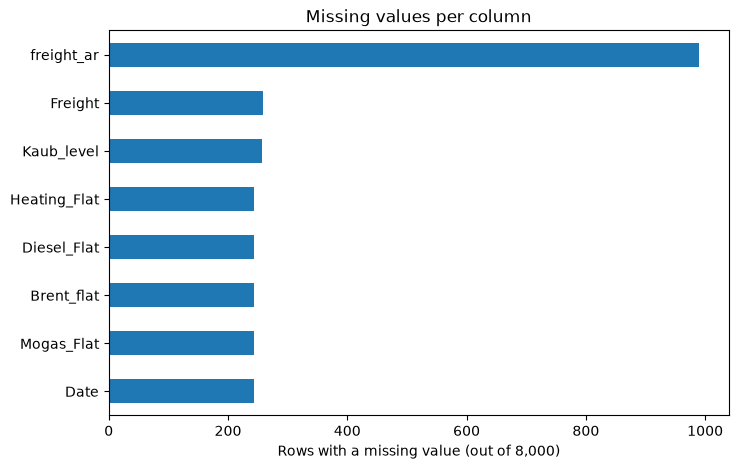

In [6]:
# Missing values visualization
print("Duplicate rows:", df_freight.duplicated().sum())
missing = df_freight.isna().sum()
missing = missing[missing > 0].sort_values()

missing.plot(kind="barh", figsize=(8, 5))
plt.title("Missing values per column")
plt.xlabel("Rows with a missing value (out of 8,000)")
plt.savefig(CHARTS_DIR / "missing.png", dpi=150)
plt.show()



Analysing missing values. We noticed that the last rows in the dataset were completly empty.

In [7]:
empty_rows = df_freight.isna().all(axis=1).sum()
print(f"Number of completely empty rows in df_freight: {empty_rows}")

Number of completely empty rows in df_freight: 244


244 rows were dropped since they were completely empty. Will that, the total number of rows was reduced to 1469

In [8]:
df_freight = df_freight.dropna(how="all")
df_freight.shape

(1469, 8)

Here we can see a brief description of the dataset after removing the completely empty rows. There are still some variables that have missing values, especially ``freight_ar``.

In [9]:
df_freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 1469 entries, 0 to 1468
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          1469 non-null   str    
 1   Freight       1454 non-null   float64
 2   Mogas_Flat    1469 non-null   float64
 3   Brent_flat    1469 non-null   float64
 4   Diesel_Flat   1469 non-null   float64
 5   Heating_Flat  1469 non-null   float64
 6   Kaub_level    1456 non-null   float64
 7   freight_ar    723 non-null    float64
dtypes: float64(7), str(1)
memory usage: 91.9 KB


In [10]:
print(f"Number of duplicate rows: {df_freight.duplicated().sum()}")

Number of duplicate rows: 0


Missing values remaining

In [11]:
df_freight.isna().sum()

Date              0
Freight          15
Mogas_Flat        0
Brent_flat        0
Diesel_Flat       0
Heating_Flat      0
Kaub_level       13
freight_ar      746
dtype: int64

In [12]:
missing_pct = (df_freight.isna().mean()*100).round(2)
print(missing_pct.sort_values(ascending=False))

freight_ar      50.78
Freight          1.02
Kaub_level       0.88
Date             0.00
Brent_flat       0.00
Mogas_Flat       0.00
Heating_Flat     0.00
Diesel_Flat      0.00
dtype: float64


As we can see the variables `Freight` and `Kaub_level` still have some missing values, but nothing significantly. On the other hand, 51% of the rows don't have any value for `freight_ar`.

In [13]:
df_freight.nunique()

Date            1469
Freight          203
Mogas_Flat      1469
Brent_flat      1469
Diesel_Flat     1469
Heating_Flat    1468
Kaub_level       406
freight_ar       284
dtype: int64

In [14]:
duplicates_hf = df_freight[df_freight.duplicated(subset=['Heating_Flat'], keep=False)]
duplicates_hf[['Date', 'Heating_Flat']].sort_values('Heating_Flat')

,Date,Heating_Flat
1196,17/11/2017,404.321314
1217,18/12/2017,404.321314


In [15]:
duplicates_hf = df_freight[df_freight.duplicated(subset=['Freight'], keep=False)]
duplicates_hf[['Date', 'Freight']].sort_values('Freight')


,Date,Freight
279,24/02/2014,31.8
280,25/02/2014,31.8
272,13/02/2014,31.8
273,14/02/2014,31.8
276,19/02/2014,31.8
...,...,...
1059,27/04/2017,NaN
1119,27/07/2017,NaN
1128,09/08/2017,NaN
1129,10/08/2017,NaN


In [16]:
df_freight[df_freight.duplicated('Freight', keep=False)].groupby('Freight')['Date'].apply(list)

Freight
31.80     [13/02/2014, 14/02/2014, 17/02/2014, 18/02/201...
32.55     [30/01/2014, 31/01/2014, 03/02/2014, 04/02/201...
34.05     [28/01/2014, 29/01/2014, 10/08/2016, 11/08/201...
34.80     [06/03/2014, 07/03/2014, 07/07/2016, 08/07/201...
35.55     [31/01/2013, 01/02/2013, 04/02/2013, 05/02/201...
                                ...                        
186.30                             [28/10/2015, 29/10/2015]
201.30                 [03/11/2015, 04/11/2015, 17/11/2015]
225.30    [06/11/2015, 09/11/2015, 10/11/2015, 11/11/201...
337.50                             [13/11/2018, 27/11/2018]
349.50                             [19/11/2018, 28/11/2018]
Name: Date, Length: 87, dtype: object

In [17]:
df_freight.describe()

,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
count,1454.000000,1469.000000,1469.000000,1469.000000,1469.000000,1456.000000,723.000000
mean,66.740880,471.307495,175.428168,452.550514,429.251464,211.656593,3.254177
std,54.903678,76.829817,49.417972,76.061052,81.264952,106.916360,1.410743
min,31.800000,265.988761,71.486202,235.426759,197.540995,25.000000,1.730000
25%,40.800000,407.779598,132.274233,393.154440,366.270631,138.000000,2.435000
50%,45.300000,482.888610,162.397599,466.190525,436.102649,198.000000,2.870000
75%,60.300000,536.367611,230.795073,511.022014,495.777277,264.000000,3.420000
max,360.450000,643.154358,267.888999,592.948663,579.071651,716.000000,8.920000


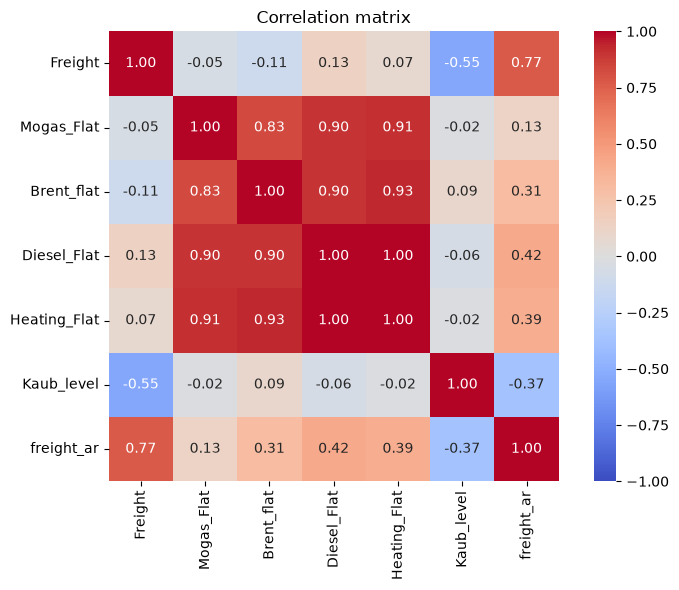

In [18]:
df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y") # convert the "Date" column to datetime format
df_freight = df_freight.set_index("Date").sort_index() # set the "Date" column as the index and sort the DataFrame

cols = df_freight.columns[:]  # selecting columns for correlation analysis
corr = df_freight[cols].corr()   

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [19]:

# derive columns from the index
df_freight["year"] = df_freight.index.year
df_freight["month"] = df_freight.index.month
df_freight["day"] = df_freight.index.day
df_freight["dayofweek"] = df_freight.index.dayofweek   # 0 = Monday
df_freight["dayofyear"] = df_freight.index.dayofyear
df_freight

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_24508\4071517752.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_freight["dayofweek"] = df_freight.index.dayofweek   # 0 = Monday
C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_24508\4071517752.py:6: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df_freight["dayofyear"] = df_freight.index.dayofyear


,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,year,month,day,dayofweek,dayofyear
Date,,,,,,,,,,,,
2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,2013,1,3,3,3
2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,2013,1,4,4,4
2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,2013,1,7,0,7
2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,2013,1,8,1,8
2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,2013,1,9,2,9
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-19,122.10,369.642473,146.882946,451.772743,415.532617,122.0,8.01,2018,12,19,2,353
2018-12-20,125.10,358.572348,138.773906,428.606619,400.189434,118.0,8.25,2018,12,20,3,354
2018-12-21,118.35,357.211272,134.676713,417.284765,390.506876,117.0,8.25,2018,12,21,4,355


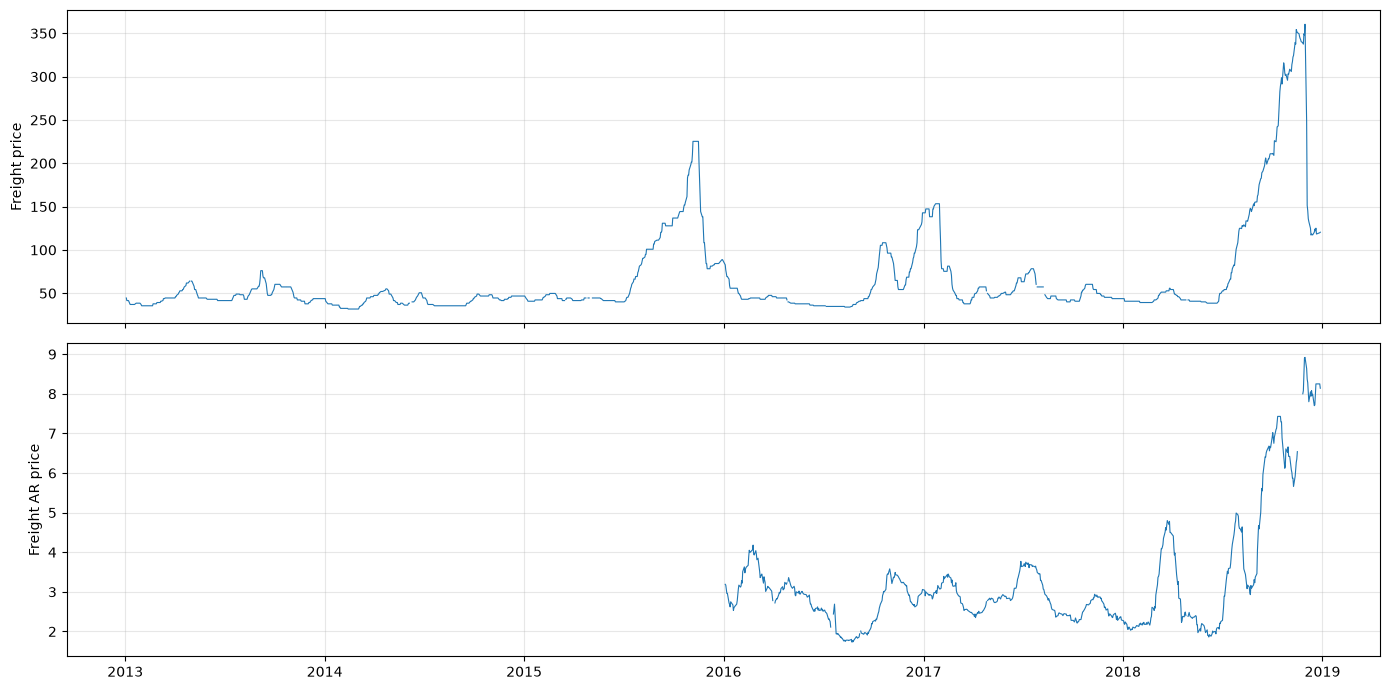

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df_freight.index, df_freight["Freight"], lw=0.8)
ax[0].set_ylabel("Freight price")

ax[1].plot(df_freight.index, df_freight["freight_ar"], lw=0.8, color="tab:blue")
ax[1].set_ylabel("Freight AR price")



for a in ax:
    a.grid(alpha=0.3)

ax[1].xaxis.set_major_locator(mdates.YearLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

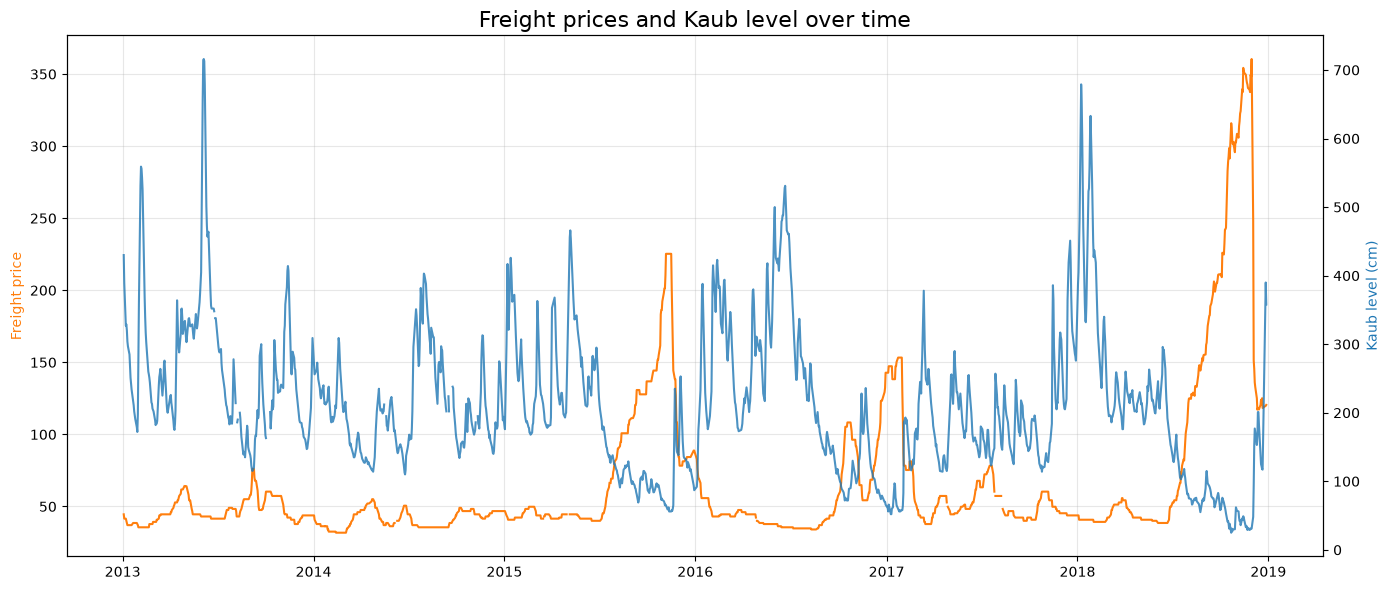

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(df_freight.index, df_freight["Freight"], lw=1.5, color="tab:orange", label="Freight price")
plt.ylabel("Freight price", color="tab:orange")
plt.grid(alpha=0.3)

plt.twinx()   # second y-axis sharing the same x-axis
plt.plot(df_freight.index, df_freight["Kaub_level"], lw=1.5, color="tab:blue", alpha=0.8, label="Kaub level")
plt.ylabel("Kaub level (cm)", color="tab:blue")

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.title("Freight prices and Kaub level over time", fontsize=16)
plt.tight_layout()
plt.show()

When Kaub level is min/max

In [22]:
cols = ["Kaub_level", "Freight"]
df_freight.loc[[df_freight["Kaub_level"].idxmin(), df_freight["Kaub_level"].idxmax()], cols]


,Kaub_level,Freight
Date,,
2018-10-22,25.0,315.90
2013-06-05,716.0,43.05


When Freight is min/max

In [23]:
cols = ["Kaub_level", "Freight"]
df_freight.loc[[df_freight["Freight"].idxmin(), df_freight["Freight"].idxmax()], cols]

,Kaub_level,Freight
Date,,
2014-02-13,207.0,31.80
2018-11-30,31.0,360.45


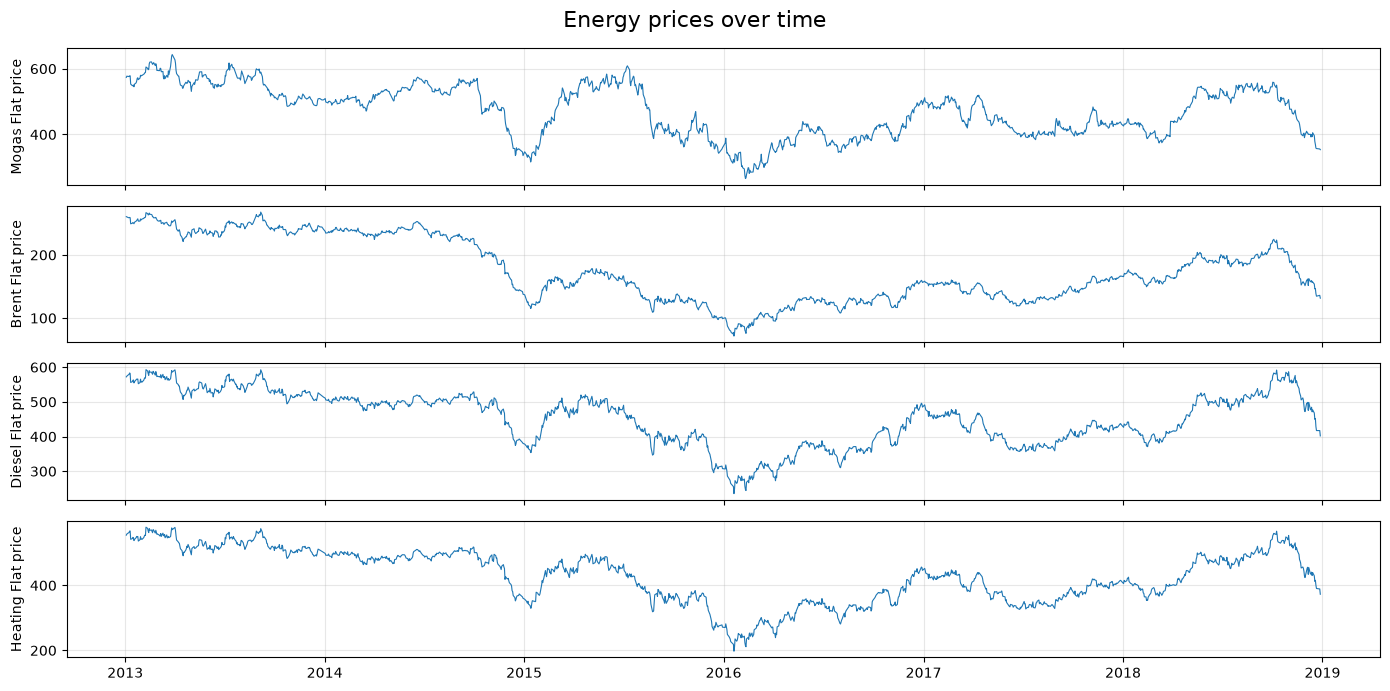

In [24]:
fig, ax = plt.subplots(4, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df_freight.index, df_freight["Mogas_Flat"], lw=0.8)
ax[0].set_ylabel("Mogas Flat price")

ax[1].plot(df_freight.index, df_freight["Brent_flat"], lw=0.8, color="tab:blue")
ax[1].set_ylabel("Brent Flat price")

ax[2].plot(df_freight.index, df_freight["Diesel_Flat"], lw=0.8, color="tab:blue")
ax[2].set_ylabel("Diesel Flat price")

ax[3].plot(df_freight.index, df_freight["Heating_Flat"], lw=0.8, color="tab:blue")
ax[3].set_ylabel("Heating Flat price")

for a in ax:
    a.grid(alpha=0.3)

ax[1].xaxis.set_major_locator(mdates.YearLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.suptitle("Energy prices over time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

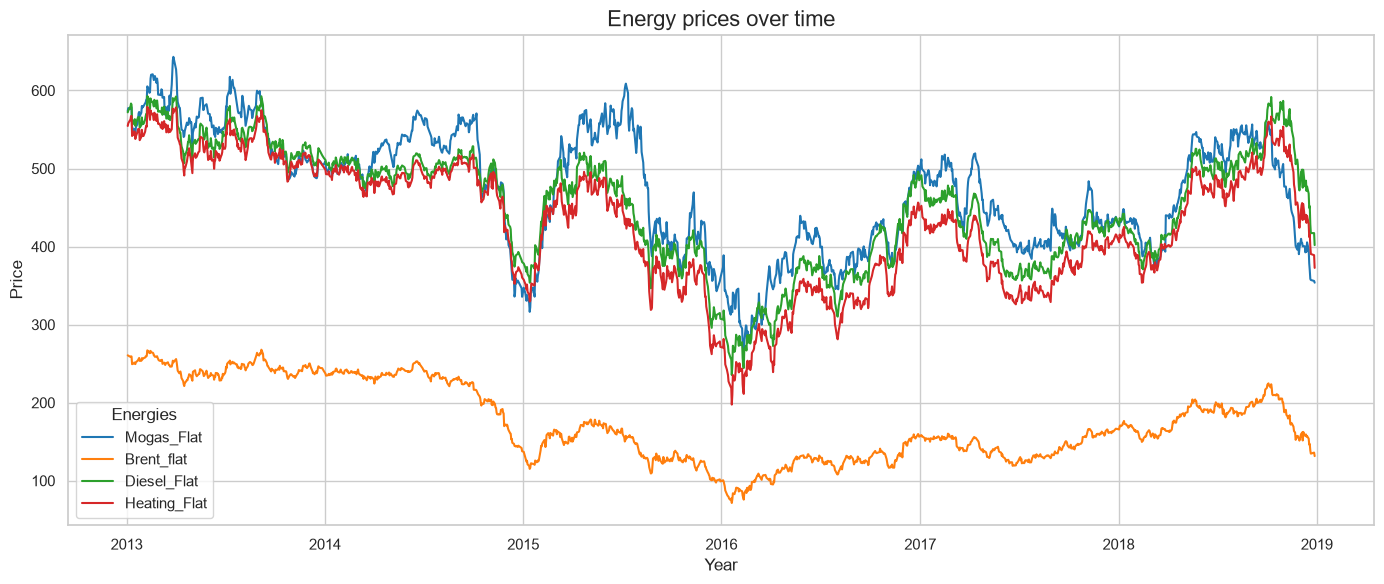

In [25]:
sns.set_theme(style="whitegrid")

cols = ["Mogas_Flat", "Brent_flat", "Diesel_Flat", "Heating_Flat"]
data = df_freight[cols] # 7-observation smoothing

plt.figure(figsize=(14, 6))
ax = sns.lineplot(data=data, palette="tab10", linewidth=1.5, dashes=False)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Year")
ax.set_ylabel("Price")
ax.set_title("Energy prices over time", fontsize=16)
ax.legend(title="Energies")
plt.tight_layout()
plt.show()

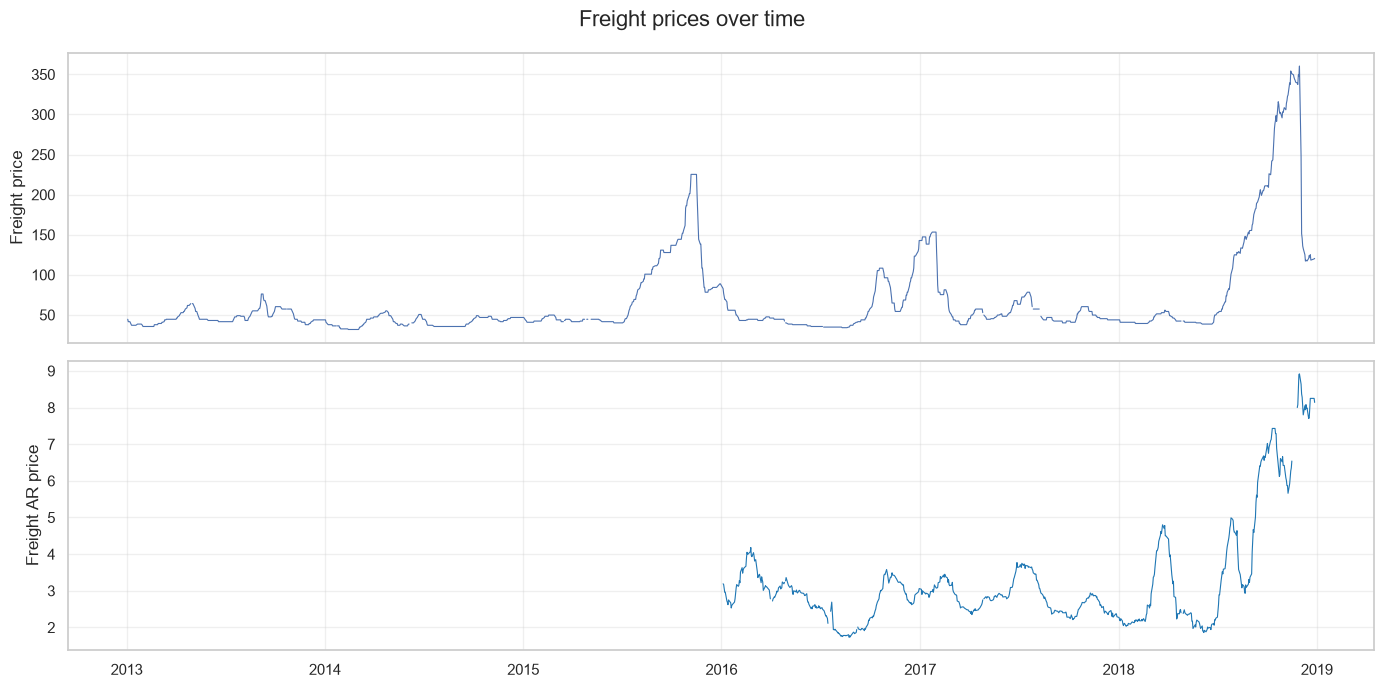

In [26]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(df_freight.index, df_freight["Freight"], lw=0.8)
ax[0].set_ylabel("Freight price")

ax[1].plot(df_freight.index, df_freight["freight_ar"], lw=0.8, color="tab:blue")
ax[1].set_ylabel("Freight AR price")

for a in ax:
    a.grid(alpha=0.3)

ax[1].xaxis.set_major_locator(mdates.YearLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.suptitle("Freight prices over time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

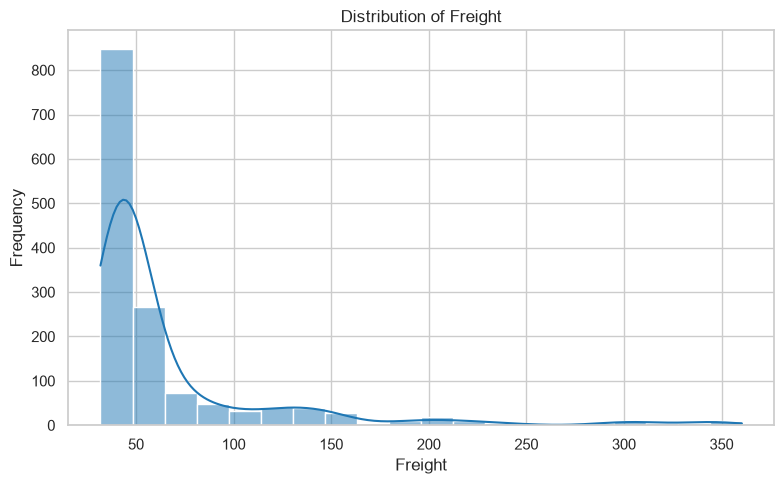

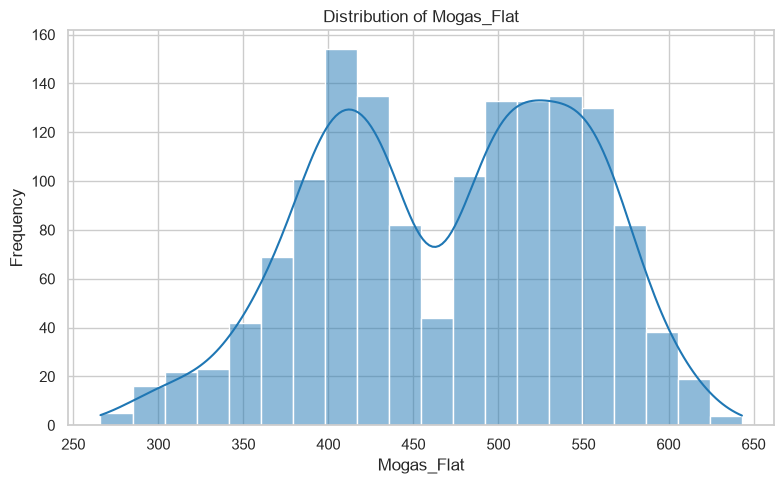

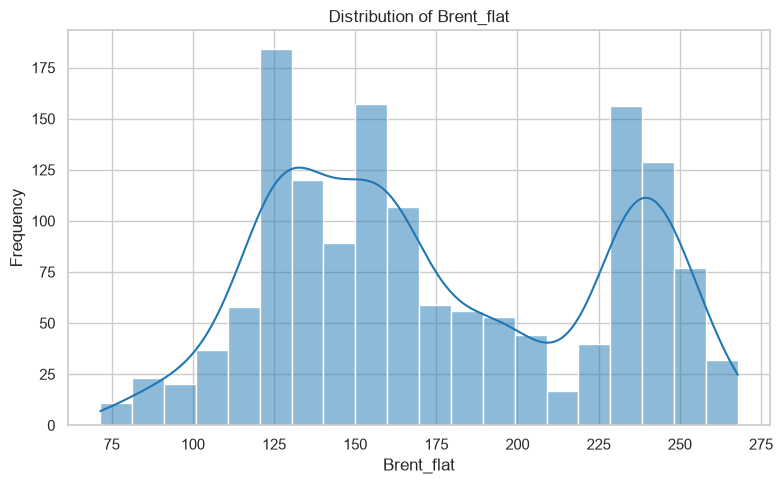

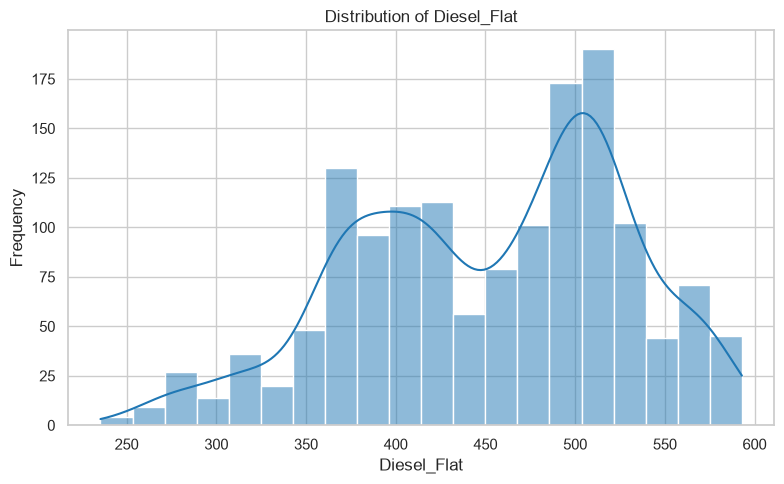

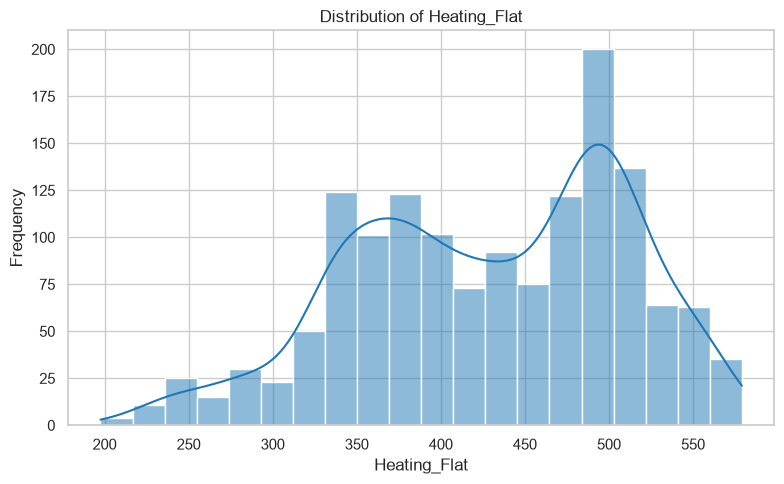

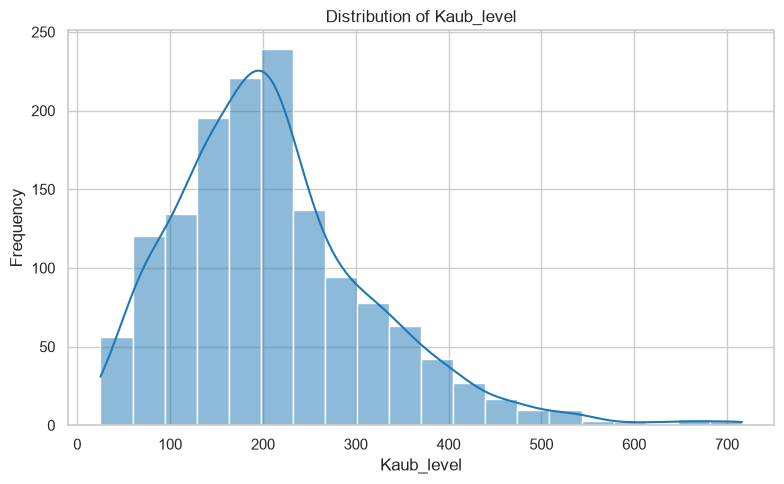

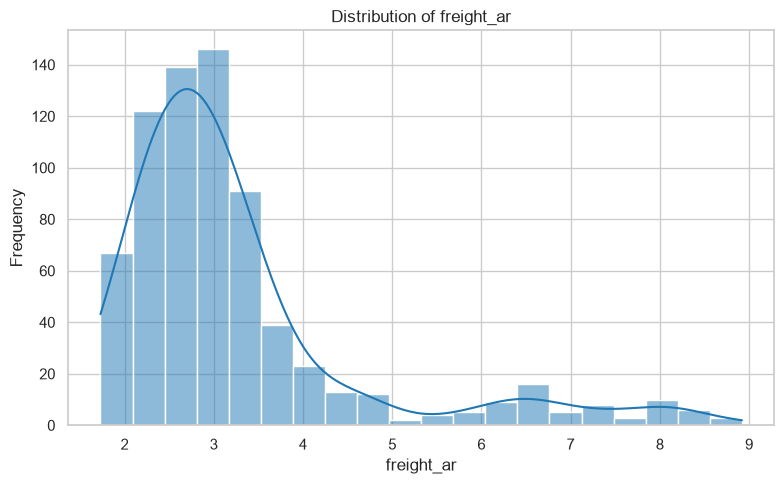

In [27]:
num_cols =["Freight", "Mogas_Flat",	"Brent_flat", "Diesel_Flat", "Heating_Flat", "Kaub_level", "freight_ar"]

for col in num_cols:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df_freight,
        color="tab:blue",
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

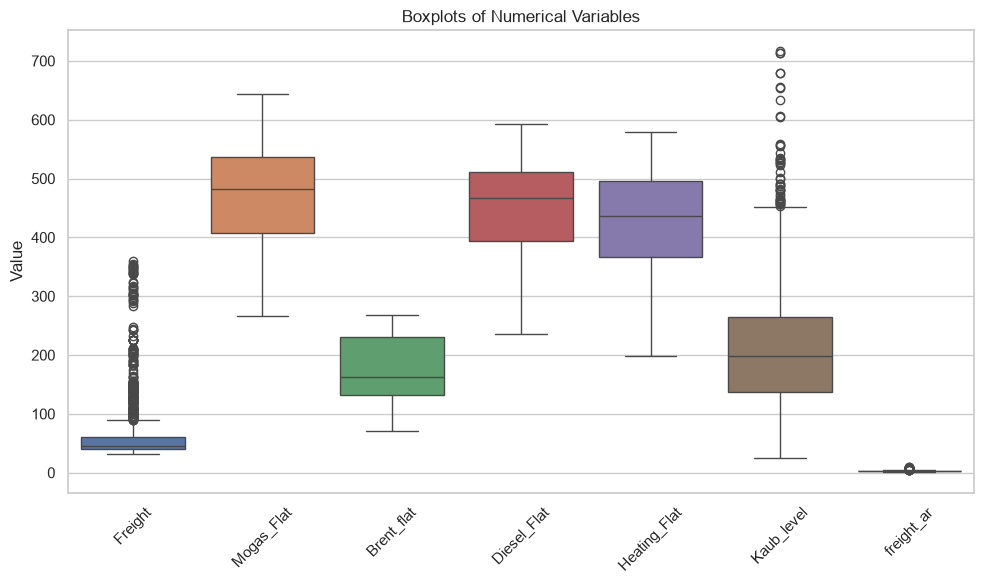

In [28]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_freight[num_cols])

plt.title("Boxplots of Numerical Variables")
plt.ylabel("Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

2.2 Weather Dataset

In [29]:
df_weather

,date,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,01/01/2009,1.0,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,...,0.0,1.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,02/01/2009,1.0,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,...,0.0,1.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,03/01/2009,1.0,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,...,0.0,1.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,04/01/2009,1.0,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,05/01/2009,1.0,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,...,0.0,1.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
print(f"Dataset shape: {df_weather.shape}")

Dataset shape: (4017, 25)


In [31]:
df_weather = df_weather.dropna(how="all")
df_weather.shape

(3652, 25)

In [32]:
df_weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 3652 entries, 0 to 3651
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  3652 non-null   str    
 1   avg_uv_index          3652 non-null   float64
 2   avgtemp               3652 non-null   float64
 3   cloudcover            3652 non-null   float64
 4   dewpoint              3652 non-null   float64
 5   feelslike             3652 non-null   float64
 6   heatindex             3652 non-null   float64
 7   humidity              3652 non-null   float64
 8   maxtemp               3652 non-null   float64
 9   mintemp               3652 non-null   float64
 10  moon_illumination     3652 non-null   float64
 11  moon_phase            3652 non-null   str    
 12  precip                3652 non-null   float64
 13  pressure              3652 non-null   float64
 14  sunhour               3652 non-null   float64
 15  totalsnow             3652 non-n

In [33]:
print(f"Number of duplicate rows: {df_weather.duplicated().sum()}")

Number of duplicate rows: 0


In [34]:
df_weather.isna().sum()

date                    0
avg_uv_index            0
avgtemp                 0
cloudcover              0
dewpoint                0
feelslike               0
heatindex               0
humidity                0
maxtemp                 0
mintemp                 0
moon_illumination       0
moon_phase              0
precip                  0
pressure                0
sunhour                 0
totalsnow               0
uv_index                0
visibility              0
weather_code            0
weather_descriptions    0
wind_degree             0
wind_dir                0
wind_speed              0
windchill               0
windgust                0
dtype: int64

In [35]:
missing_pct = (df_weather.isna().mean()*100).round(2)
print(missing_pct.sort_values(ascending=False))

date                    0.0
avg_uv_index            0.0
avgtemp                 0.0
cloudcover              0.0
dewpoint                0.0
feelslike               0.0
heatindex               0.0
humidity                0.0
maxtemp                 0.0
mintemp                 0.0
moon_illumination       0.0
moon_phase              0.0
precip                  0.0
pressure                0.0
sunhour                 0.0
totalsnow               0.0
uv_index                0.0
visibility              0.0
weather_code            0.0
weather_descriptions    0.0
wind_degree             0.0
wind_dir                0.0
wind_speed              0.0
windchill               0.0
windgust                0.0
dtype: float64


In [36]:
df_weather.nunique() 

date                    3652
avg_uv_index               1
avgtemp                   43
cloudcover               101
dewpoint                  42
feelslike                 54
heatindex                 49
humidity                  59
maxtemp                   45
mintemp                   42
moon_illumination        101
moon_phase                 8
precip                    11
pressure                  60
sunhour                   93
totalsnow                 40
uv_index                   1
visibility                11
weather_code              17
weather_descriptions      17
wind_degree              357
wind_dir                  16
wind_speed                32
windchill                 50
windgust                  51
dtype: int64

In [37]:
df_freight.describe()

,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,year,month,day,dayofweek,dayofyear
count,1454.000000,1469.000000,1469.000000,1469.000000,1469.000000,1456.000000,723.000000,1469.000000,1469.000000,1469.000000,1469.000000,1469.000000
mean,66.740880,471.307495,175.428168,452.550514,429.251464,211.656593,3.254177,2015.502383,6.503744,15.742001,2.027229,182.497617
std,54.903678,76.829817,49.417972,76.061052,81.264952,106.916360,1.410743,1.704946,3.437376,8.618513,1.401855,104.756748
min,31.800000,265.988761,71.486202,235.426759,197.540995,25.000000,1.730000,2013.000000,1.000000,1.000000,0.000000,2.000000
25%,40.800000,407.779598,132.274233,393.154440,366.270631,138.000000,2.435000,2014.000000,3.000000,8.000000,1.000000,90.000000
50%,45.300000,482.888610,162.397599,466.190525,436.102649,198.000000,2.870000,2016.000000,7.000000,16.000000,2.000000,185.000000
75%,60.300000,536.367611,230.795073,511.022014,495.777277,264.000000,3.420000,2017.000000,9.000000,23.000000,3.000000,273.000000
max,360.450000,643.154358,267.888999,592.948663,579.071651,716.000000,8.920000,2018.000000,12.000000,31.000000,4.000000,365.000000


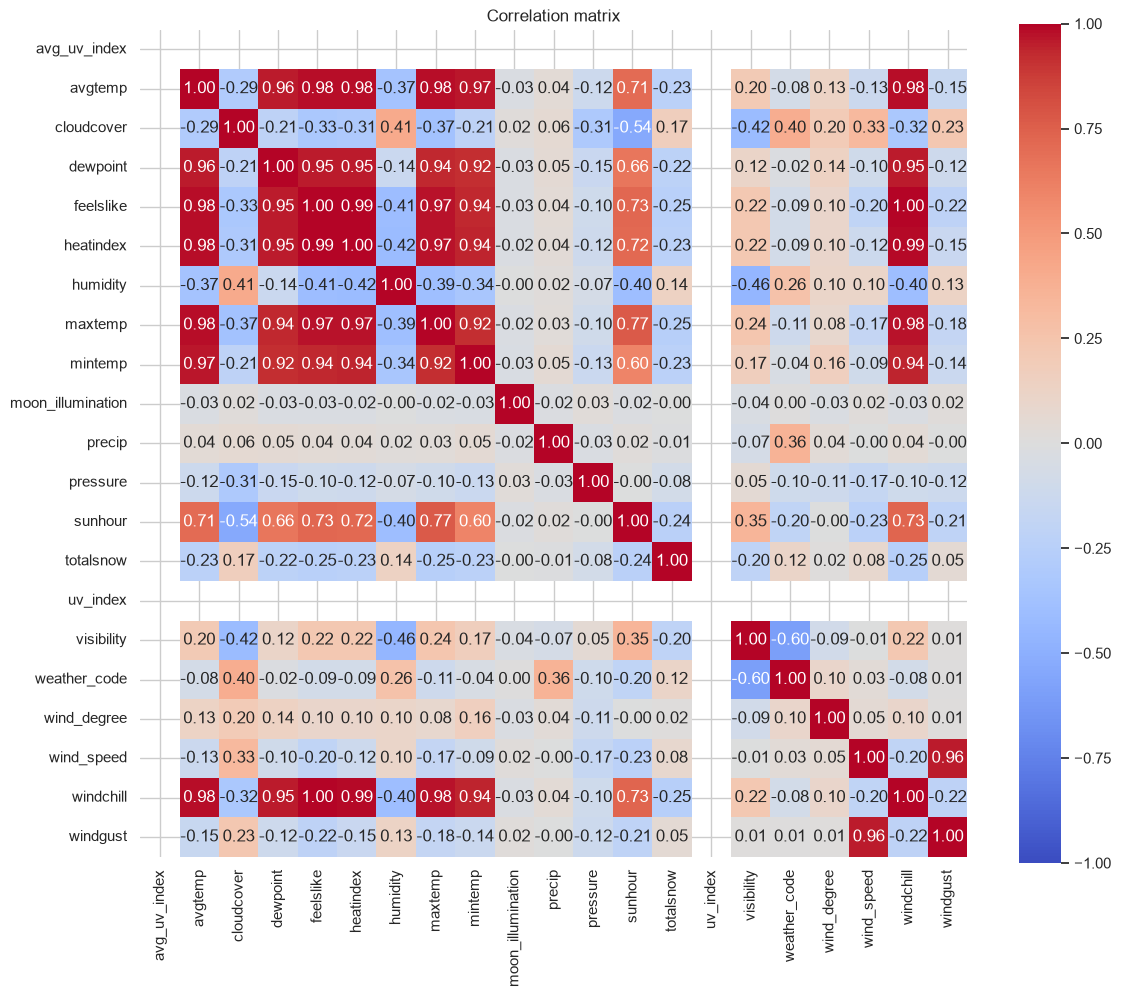

In [38]:
df_weather["date"] = pd.to_datetime(df_weather["date"], format="%d/%m/%Y")
df_weather = df_weather.set_index("date").sort_index()
df_weather = df_weather.loc["2013":"2018"] # selecting data from 2013 to 2018 for analysis                
cols = df_weather.select_dtypes(include=[np.number]).columns# selecting columns for correlation analysis
corr = df_weather[cols].corr()   


plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [39]:
# derive columns from the index
df_weather["year"] = df_weather.index.year
df_weather["month"] = df_weather.index.month
df_weather["day"] = df_weather.index.day
df_weather["dayofweek"] = df_weather.index.dayofweek   # 0 = Monday
df_weather["dayofyear"] = df_weather.index.dayofyear
df_weather

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_24508\4074232263.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_weather["dayofweek"] = df_weather.index.dayofweek   # 0 = Monday
C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_24508\4074232263.py:6: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df_weather["dayofyear"] = df_weather.index.dayofyear


,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,moon_illumination,...,wind_degree,wind_dir,wind_speed,windchill,windgust,year,month,day,dayofweek,dayofyear
date,,,,,,,,,,,,,,,,,,,,,
2013-01-01,1.0,3.0,97.0,3.0,0.0,4.0,97.0,5.0,0.0,68.0,...,234.0,SW,13.0,0.0,23.0,2013,1,1,1,1
2013-01-02,1.0,2.0,19.0,-1.0,-1.0,0.0,93.0,5.0,-2.0,60.0,...,121.0,ESE,4.0,-1.0,9.0,2013,1,2,2,2
2013-01-03,1.0,2.0,100.0,1.0,1.0,3.0,85.0,4.0,-1.0,53.0,...,245.0,WSW,7.0,1.0,14.0,2013,1,3,3,3
2013-01-04,1.0,4.0,100.0,4.0,3.0,5.0,98.0,6.0,3.0,46.0,...,283.0,WNW,6.0,3.0,12.0,2013,1,4,4,4
2013-01-05,1.0,4.0,58.0,3.0,3.0,3.0,95.0,6.0,1.0,38.0,...,311.0,NW,4.0,3.0,8.0,2013,1,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-27,1.0,1.0,48.0,-11.0,-1.0,1.0,40.0,4.0,-1.0,62.0,...,190.0,S,6.0,-1.0,11.0,2018,12,27,3,361
2018-12-28,1.0,1.0,10.0,-2.0,0.0,1.0,79.0,4.0,0.0,55.0,...,225.0,SW,3.0,0.0,5.0,2018,12,28,4,362
2018-12-29,1.0,0.0,8.0,-2.0,-2.0,0.0,85.0,3.0,-1.0,48.0,...,205.0,SSW,6.0,-2.0,12.0,2018,12,29,5,363


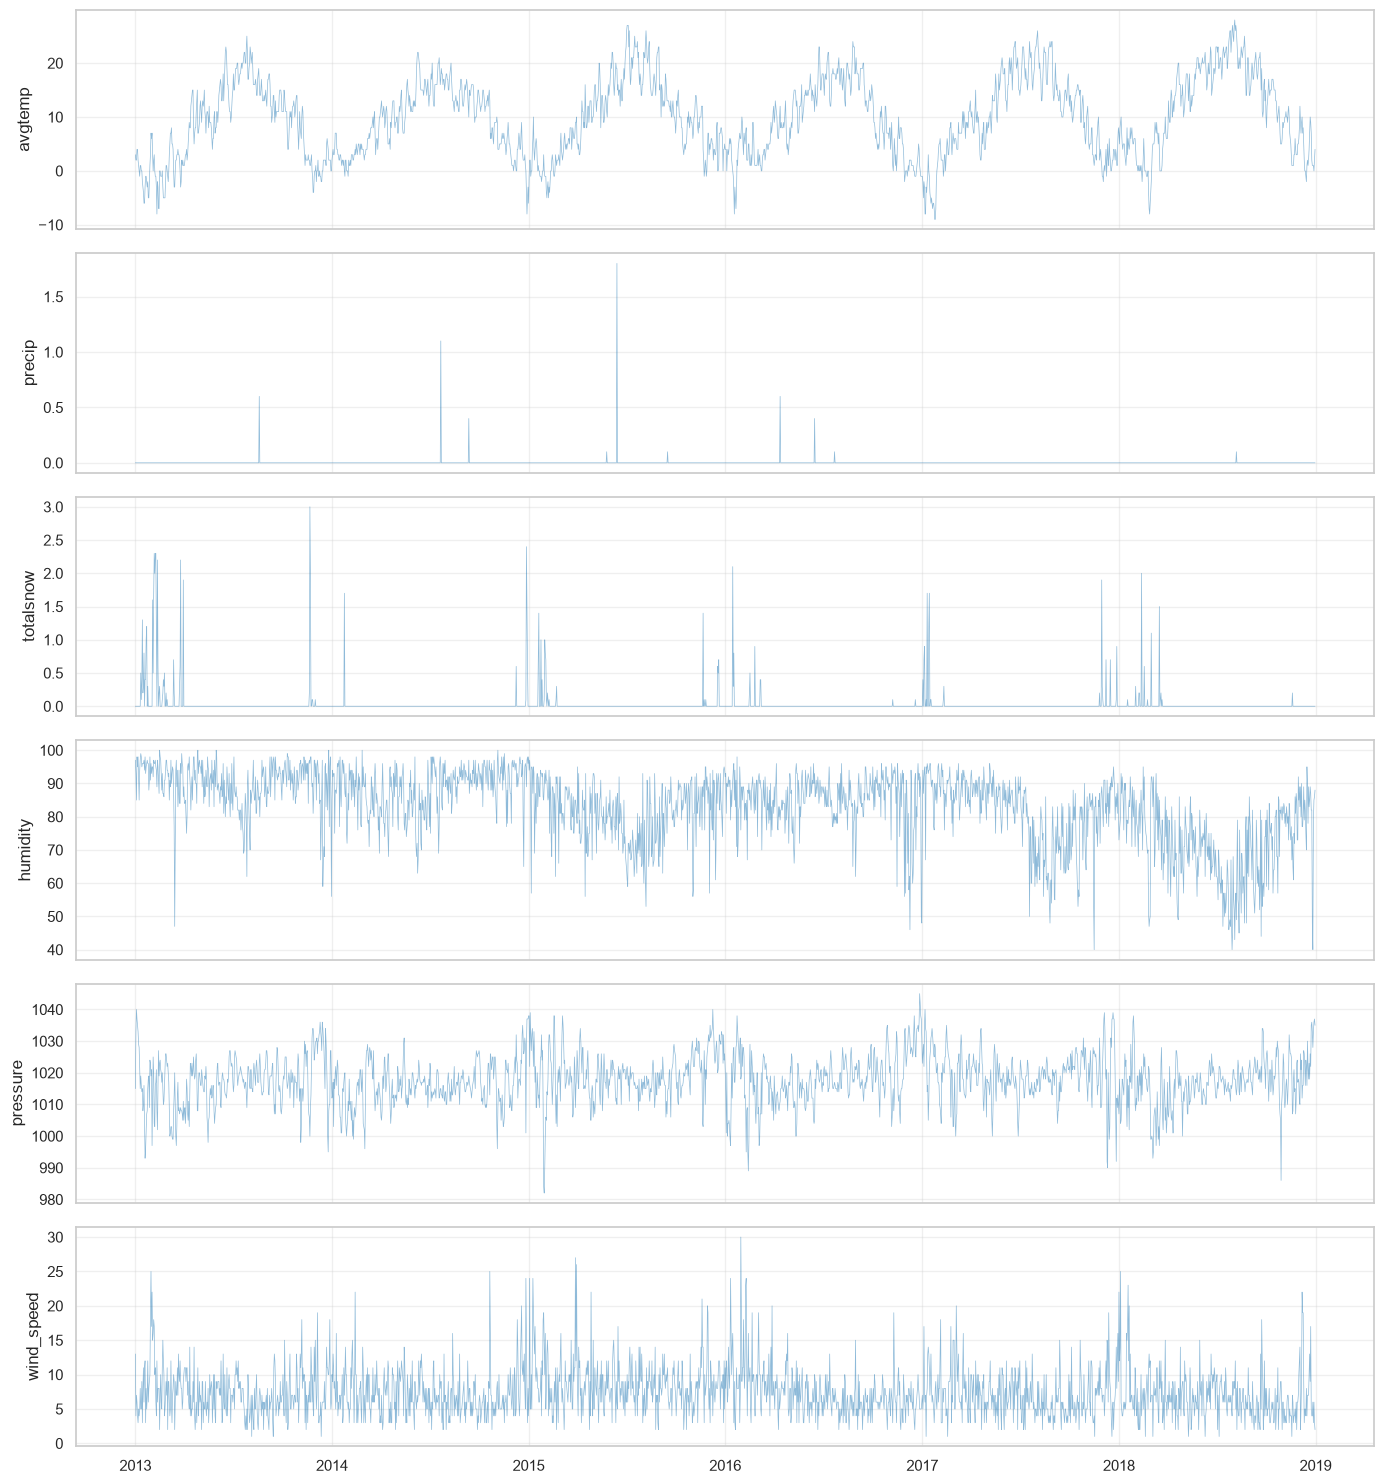

In [40]:
cols = ["avgtemp", "precip", "totalsnow", "humidity", "pressure", "wind_speed"]

fig, axes = plt.subplots(len(cols), 1, figsize=(14, 2.5 * len(cols)), sharex=True)
for a, v in zip(axes, cols):
    a.plot(df_weather.index, df_weather[v], lw=0.5, alpha=0.5, color="tab:blue")  
    a.set_ylabel(v)
    a.grid(alpha=0.3)

axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

In [41]:
df_weather["year"].unique()

array([2013, 2014, 2015, 2016, 2017, 2018], dtype=int32)

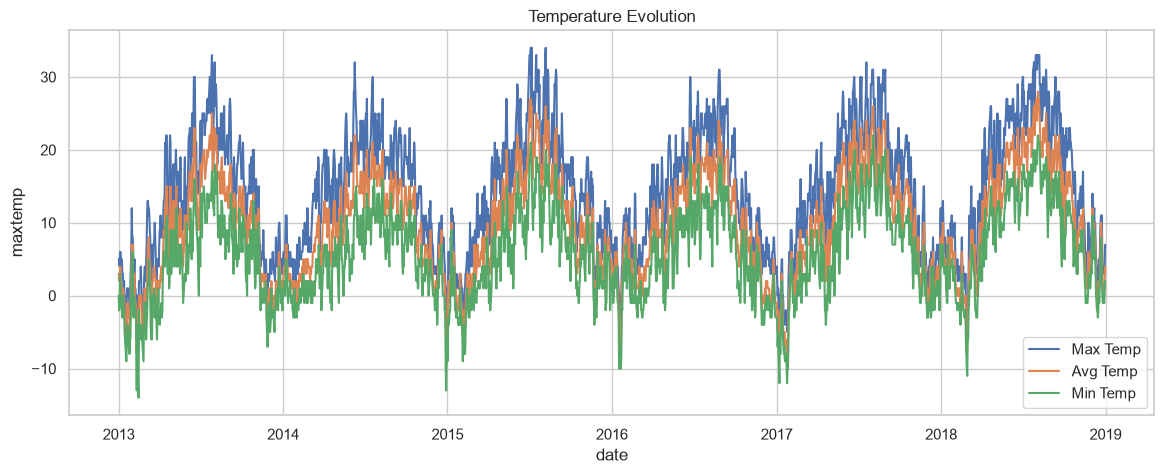

In [42]:
plt.figure(figsize=(14, 5))

sns.lineplot(data=df_weather, x="date", y="maxtemp", label="Max Temp")
sns.lineplot(data=df_weather, x="date", y="avgtemp", label="Avg Temp")
sns.lineplot(data=df_weather, x="date", y="mintemp", label="Min Temp")

plt.title("Temperature Evolution")
plt.show()

In [43]:
df_weather["month"] = df_weather["date"].dt.month
df_weather["year"] = df_weather["date"].dt.year

KeyError: 'date'